# Configurable Deployment Policy Solver Task B

Accept a Boolean policy over `P`, `A`, and `W`; combine it with the original deployment rules; generate a phase oracle with `PhaseOracleGate`; and verify zero, one, or multiple solutions.

**Bit order:** configurations are written as `P A W` (left to right).

**Policy syntax:** `P`, `A`, `W`, `&` (and), `|` (or), `^` (xor), `~` (not) and parentheses. Precedence follows Python, not left-to-right reading: `~` first, then `&`, then `^`, then `|`. For example `P | A & W` means `P | (A & W)`.

**Dependencies:** `qiskit` (a recent version that provides `PhaseOracleGate`), `qiskit-aer`, and `matplotlib`.

## Setup

Install the required packages once before running the notebook:

```bash
pip install "qiskit>=2.0" qiskit-aer matplotlib
```

**Requirements:** Python 3.9 or newer, `qiskit` (version 2.0 or newer, which provides `PhaseOracleGate`), `qiskit-aer` and `matplotlib`.

In [ ]:
import re
import ast
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PhaseOracleGate, grover_operator
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

def original(p, a, w):
    return bool((p or w) and ((not p) or a) and not (p and w))


BASE = "(P | W) & (~P | A) & ~(P & W)"

def configs():
    return [format(i, "03b") for i in range(8)]

def bits(x):
    return tuple(map(int, x))  # P, A, W

valid_original = [x for x in configs() if original(*bits(x))]
print("Original valid configurations:", valid_original)

Original valid configurations: ['001', '011', '110']


## 2. Policy input and safe evaluation

The evaluator accepts only `P`, `A`, `W`, Boolean operators, and parentheses; arbitrary Python expressions are rejected. Each kind of mistake gets its own message (unknown variable, Python keywords such as `and`, stray characters, bad syntax).

In [ ]:
# 2. Parse only the allowed Boolean syntax
VARS = {"P", "A", "W"}
ALLOWED_CHARS = set("&|^~() \t")
NAME = r"[A-Za-z_][A-Za-z0-9_]*"

def policy_fn(expr):
    if not isinstance(expr, str) or not expr.strip():
        raise ValueError("Policy is empty. Enter an expression such as 'P & A & ~W'.")

    names = re.findall(NAME, expr)
    keywords = [n for n in names if n.lower() in {"and", "or", "not"}]
    if keywords:
        raise ValueError(f"Python keyword(s) {sorted(set(keywords))} are not supported. Use &, |, ~ instead.")
    unknown = sorted({n for n in names if n not in VARS})
    if unknown:
        raise ValueError(f"Unknown variable(s): {unknown}. Only P, A, W (uppercase) are allowed.")
    stray = sorted(set(re.sub(NAME, "", expr)) - ALLOWED_CHARS)
    if stray:
        raise ValueError(f"Unsupported character(s): {stray}. Use only P, A, W, &, |, ^, ~ and parentheses.")

    try:
        tree = ast.parse(expr.strip(), mode="eval")
    except SyntaxError as e:
        raise ValueError("Invalid policy syntax. Check operators and parentheses.") from e

    allowed = (ast.Expression, ast.Name, ast.Load, ast.UnaryOp, ast.Invert,
               ast.BinOp, ast.BitAnd, ast.BitOr, ast.BitXor)
    for node in ast.walk(tree):
        if not isinstance(node, allowed):
            raise ValueError("Unsupported expression. Use only Boolean variables and operators.")

    def run(node, env):
        if isinstance(node, ast.Expression):
            return run(node.body, env)
        if isinstance(node, ast.Name):
            return env[node.id]
        if isinstance(node, ast.UnaryOp) and isinstance(node.op, ast.Invert):
            return not run(node.operand, env)
        if isinstance(node, ast.BinOp):
            left, right = run(node.left, env), run(node.right, env)
            if isinstance(node.op, ast.BitAnd): return left and right
            if isinstance(node.op, ast.BitOr): return left or right
            if isinstance(node.op, ast.BitXor): return left != right
        raise ValueError("Invalid Boolean expression.")

    return lambda p, a, w: bool(run(tree, {"P": bool(p), "A": bool(a), "W": bool(w)}))

# The Boolean string embedded in the oracle must describe the same rules as original().
_base = policy_fn(BASE)
assert all(_base(*bits(x)) == original(*bits(x)) for x in configs()), "BASE and original() disagree"
print("BASE matches original() on all 8 configurations.")

BASE matches original() on all 8 configurations.


## 3. Classical ground truth

Exhaustively check all eight configurations first. This gives the exact solution count M (needed to choose the number of Grover rounds) and is the only valid proof that a policy is impossible.

In [ ]:
# 3. Combine original rules with each user policy
tests = {
    "One: API + auth, no worker": "P & A & ~W",
    "Several: auth required": "A",
    "None: API + worker together": "P & W",
}

def solve_classically(expr):
    policy = policy_fn(expr)
    return [x for x in configs()
            if original(*bits(x)) and policy(*bits(x))]

expected = {name: solve_classically(expr) for name, expr in tests.items()}
for name, expr in tests.items():
    print(f"{name:28} | {expr:12} | {expected[name]} (M={len(expected[name])})")

# Check the three required outcomes: exactly one, more than one, none.
assert len(expected["One: API + auth, no worker"]) == 1
assert len(expected["Several: auth required"]) > 1
assert len(expected["None: API + worker together"]) == 0

# Invalid policies are rejected with a specific message.
print()
for bad in ["", "P & UNKNOWN", "P and A", "P && A", "(P & A", "P & 1", "p & a", "__import__('os')"]:
    try:
        policy_fn(bad)
        print(f"{bad!r:22} -> ACCEPTED (unexpected)")
    except ValueError as err:
        print(f"{bad!r:22} -> {err}")

One: API + auth, no worker   | P & A & ~W   | ['110'] (M=1)
Several: auth required       | A            | ['011', '110'] (M=2)
None: API + worker together  | P & W        | [] (M=0)

''                     -> Policy is empty. Enter an expression such as 'P & A & ~W'.
'P & UNKNOWN'          -> Unknown variable(s): ['UNKNOWN']. Only P, A, W (uppercase) are allowed.
'P and A'              -> Python keyword(s) ['and'] are not supported. Use &, |, ~ instead.
'P && A'               -> Invalid policy syntax. Check operators and parentheses.
'(P & A'               -> Invalid policy syntax. Check operators and parentheses.
'P & 1'                -> Unsupported character(s): ['1']. Use only P, A, W, &, |, ^, ~ and parentheses.
'p & a'                -> Unknown variable(s): ['a', 'p']. Only P, A, W (uppercase) are allowed.
"__import__('os')"     -> Unknown variable(s): ['__import__', 'os']. Only P, A, W (uppercase) are allowed.


## 4. Build and verify the generated phase oracle

`PhaseOracleGate` marks assignments satisfying the **combined** Boolean expression `(BASE) & (policy)`. Before running Grover, the oracle is checked directly: applied to the uniform superposition, it must flip the sign of exactly the classically expected configurations and no others (this also covers the zero-solution case, where nothing may be marked).

With M solutions out of 8, `θ = arcsin(√(M/8))` and the number of Grover rounds is `round(π/(4θ) − ½)`.

In [ ]:
# 4. Qiskit oracle, oracle verification and Grover circuit
def qiskit_expr(policy):
    return f"({BASE}) & ({policy})"

def make_oracle(expr):
    oracle = QuantumCircuit(3)
    oracle.append(PhaseOracleGate(expr, var_order=["P", "A", "W"]), range(3))
    return oracle

def marked_configs(expr):
    """Configurations (P A W) whose amplitude gets a minus sign from the oracle."""
    qc = QuantumCircuit(3)
    qc.h(range(3))
    qc.compose(make_oracle(expr), inplace=True)
    sv = Statevector(qc).data
    # Qiskit qubit 0 is P, so reverse the little-endian bit string to read P A W.
    return sorted(format(i, "03b")[::-1] for i, amp in enumerate(sv) if amp.real < 0)

def grover_circuit(expr, m):
    oracle = make_oracle(expr)
    qc = QuantumCircuit(3, 3)
    qc.h(range(3))

    if m:
        theta = np.arcsin(np.sqrt(m / 8))
        rounds = max(0, round(np.pi / (4 * theta) - 0.5))
        qc.compose(grover_operator(oracle).power(rounds), inplace=True)
    else:
        rounds = 0

    qc.measure(range(3), range(3))
    return qc, rounds

# Verify that the generated oracle marks exactly the expected configurations.
for name, policy in tests.items():
    got = marked_configs(qiskit_expr(policy))
    assert got == sorted(expected[name]), f"{name}: oracle marks {got}, expected {expected[name]}"
    print(f"{name:12} oracle marks {got}  == classical {expected[name]}")

print("\nQiskit version:", __import__("qiskit").__version__)

One: API + auth, no worker oracle marks ['110']  == classical ['110']
Several: auth required oracle marks ['011', '110']  == classical ['011', '110']
None: API + worker together oracle marks []  == classical []

Qiskit version: 2.6.2


## 5. Solve, verify and report

`solve()` handles the three outcomes:
- **Invalid policy:** reported with the reason; nothing is run.
- **No solution (M = 0):** established by the exhaustive classical check. A Grover run that finds nothing would not prove impossibility, so none is needed.
- **One or more solutions:** run Grover, take the most frequent measured configuration, and verify it against both the original rules and the policy before reporting it by feature name.

In [ ]:
# 5. Run all three cases
sim = AerSimulator()
NAMES = ["Public API", "Authentication", "Background worker"]
results = {}

def solve(name, policy, shots=1024, seed=7):
    print(f"=== {name}: policy '{policy}' ===")
    try:
        expected_cfgs = solve_classically(policy)
    except ValueError as err:
        print(f"Invalid policy: {err}\n")
        return None

    if not expected_cfgs:
        results[name] = {}
        print("NO SOLUTION: no configuration satisfies the original rules and this policy.")
        print("Confirmed by exhaustive classical check of all 8 configurations.\n")
        return None

    m = len(expected_cfgs)
    qc, rounds = grover_circuit(qiskit_expr(policy), m)
    counts = sim.run(transpile(qc, sim), shots=shots, seed_simulator=seed).result().get_counts()
    # Qiskit prints classical bits as W A P (q0 -> c0), so reverse keys to show P A W.
    counts_paw = {key[::-1]: value for key, value in counts.items()}
    results[name] = counts_paw

    theta = np.arcsin(np.sqrt(m / 8))
    theory = np.sin((2 * rounds + 1) * theta) ** 2
    hits = {x: counts_paw.get(x, 0) for x in expected_cfgs}
    observed = sum(hits.values()) / shots

    best = max(counts_paw, key=counts_paw.get)
    p = policy_fn(policy)
    assert original(*bits(best)) and p(*bits(best)), f"Measured {best} violates the requirements"

    print(f"M={m}, Grover rounds={rounds}")
    print("  expected solutions:", expected_cfgs)
    print("  valid measured counts:", hits)
    print(f"  valid fraction: {observed:.2%} (theory {theory:.2%})")
    print(f"  most frequent result: {best} -> verified against original rules and policy")
    for feature, bit in zip(NAMES, best):
        print(f"    {feature}: {'Enabled' if bit == '1' else 'Disabled'}")
    print()
    return best

for name, policy in tests.items():
    solve(name, policy)

# An invalid policy is reported clearly and does not crash the solver.
solve("Invalid input", "P & UNKNOWN")

=== One: API + auth, no worker: policy 'P & A & ~W' ===
M=1, Grover rounds=2
  expected solutions: ['110']
  valid measured counts: {'110': 960}
  valid fraction: 93.75% (theory 94.53%)
  most frequent result: 110 -> verified against original rules and policy
    Public API: Enabled
    Authentication: Enabled
    Background worker: Disabled

=== Several: auth required: policy 'A' ===
M=2, Grover rounds=1
  expected solutions: ['011', '110']
  valid measured counts: {'011': 497, '110': 527}
  valid fraction: 100.00% (theory 100.00%)
  most frequent result: 110 -> verified against original rules and policy
    Public API: Enabled
    Authentication: Enabled
    Background worker: Disabled

=== None: API + worker together: policy 'P & W' ===
NO SOLUTION: no configuration satisfies the original rules and this policy.
Confirmed by exhaustive classical check of all 8 configurations.

=== Invalid input: policy 'P & UNKNOWN' ===
Invalid policy: Unknown variable(s): ['UNKNOWN']. Only P, A, W (

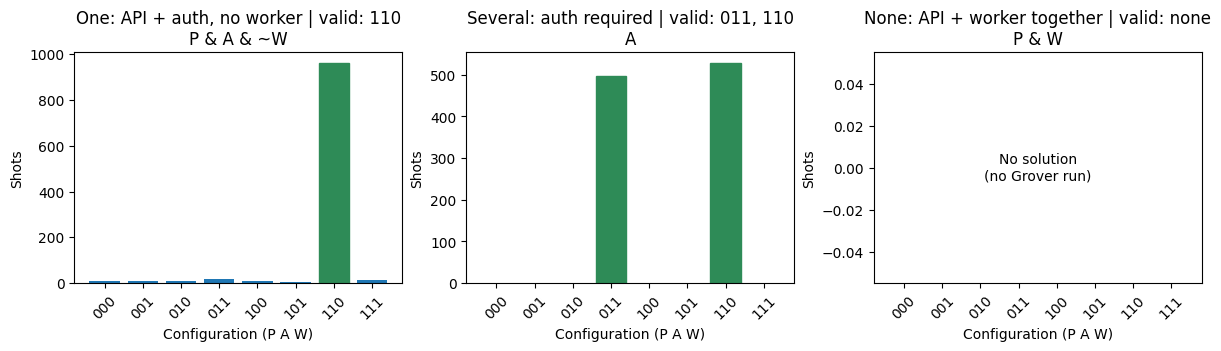

In [ ]:
# 6. Visualize measured distributions (P-A-W order)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), constrained_layout=True)

for ax, (name, policy) in zip(axes, tests.items()):
    counts = results[name]
    labels = configs()
    values = [counts.get(x, 0) for x in labels]
    bars = ax.bar(labels, values)
    for bar, x in zip(bars, labels):
        if x in expected[name]:
            bar.set_color("seagreen")
    valid = ", ".join(expected[name]) if expected[name] else "none"
    ax.set_title(f"{name} | valid: {valid}\n{policy}")
    ax.set_xlabel("Configuration (P A W)")
    ax.set_ylabel("Shots")
    ax.tick_params(axis="x", rotation=45)
    if not expected[name]:
        ax.text(0.5, 0.5, "No solution\n(no Grover run)", ha="center", va="center",
                transform=ax.transAxes)

plt.show()

### Interpretation of the test policies

The original rules leave three valid configurations: `001`, `011` and `110`. Each policy is applied on top of these.

- **One: API + auth, no worker (`P & A & ~W`).** The policy requires the API on, authentication on and the worker off, which only `110` satisfies. The combined constraints have M = 1 solution, so Grover uses 2 rounds and the success probability is about 94.5%. The simulation returned `110` in 93.75% of shots, and the verified result is Public API enabled, Authentication enabled, Background worker disabled.
- **Several: auth required (`A`).** The policy only requires authentication, which `011` and `110` satisfy, while `001` is removed because it has authentication off. The combined constraints have M = 2 solutions, so Grover uses 1 round and the theoretical success probability is 100%. The simulation returned only `011` and `110`, in roughly equal numbers. Either one is a correct answer, so a single run may return either.
- **None: API + worker together (`P & W`).** The policy requires the API and the worker to run together, which the original capacity rule forbids, so no configuration can satisfy both. The exhaustive classical check of all eight configurations proves this, so the solver reports that no configuration exists and runs no Grover search. Failed quantum samples alone would not prove impossibility.